# Mission 3: Historical Reconstruction of Market Expectations

**Author:** Justine RENAUD  
**Project:** PI² P153_T2 — Pricing the Fed: Extracting Monetary Policy Expectations from Market Data  
**Institution:** ESILV — Financial Engineering (IF-A5)  
**Academic Supervisor:** Mr. Martino Grasselli (DVHE)

This notebook uses daily 30-Day Fed Funds futures prices to estimate market expectations 30, 7 and 1 day before FOMC meetings. The estimates are then compared with the decisions. Eight meetings are studied in detail, followed by a wider analysis of scheduled meetings from 2015 to 2026.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

# Run this notebook from the project folder or from its notebooks folder.
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data"
HISTORY = DATA / "historical_reconstruction"
FIGURES = ROOT / "figures"

# Daily futures settlement prices (Bloomberg, one column per contract)
ff = pd.read_csv(
    DATA / "fed_funds_futures_history.csv",
    usecols=["date", "contract", "px_settle"],
    parse_dates=["date"],
)
ff["px_settle"] = pd.to_numeric(ff["px_settle"], errors="coerce")
px = ff.dropna().pivot_table(
    index="date", columns="contract", values="px_settle", aggfunc="last"
)

# Daily EFFR fixings (Bloomberg)
effr = pd.read_csv(DATA / "reference_rates_bloomberg.csv", parse_dates=["date"])
effr = effr.set_index("date")["effr"].dropna()

# Policy rate: midpoint of the Fed target range (FRED, 2015-2026)
policy_rate = pd.read_csv(DATA / "fed_rates.csv", parse_dates=["observation_date"])
policy_rate = policy_rate.set_index("observation_date")["target_midpoint"].dropna()

# FOMC calendar
events = pd.read_csv(DATA / "fomc_events_history_1990_2026.csv", parse_dates=["event_date"])
scheduled = events.loc[events["event_type"] == "FOMC_SCHEDULED", "event_date"]

print(f"{px.shape[1]} contracts from {px.index.min():%Y-%m-%d} to {px.index.max():%Y-%m-%d}")
print(f"{len(effr):,} daily EFFR fixings")
print(f"{len(scheduled)} scheduled FOMC meetings in the calendar file")
print(f"Policy rate from {policy_rate.index.min():%Y-%m-%d} to {policy_rate.index.max():%Y-%m-%d}")

468 contracts from 1990-01-02 to 2026-11-11
9,364 daily EFFR fixings
295 scheduled FOMC meetings in the calendar file
Policy rate from 2015-01-01 to 2026-11-09


## 1. Checking the data

Fed Funds futures prices and daily EFFR fixings come from Bloomberg exports. The policy rate is the midpoint of the Fed target range, using the FRED data in `fed_rates.csv`. This series starts in 2015, so the analysis covers 2015–2026.

The price must be the settlement observed on the selected date, not the final contract price. As a check, the September 2024 contract's last price is compared with the realised average EFFR for that month.

In [2]:
def contract_id(month):
    # Example: September 2024 is FFU24
    month_code = "FGHJKMNQUVXZ"[month.month - 1]
    return f"FF{month_code}{month.year % 100:02d}"


september_contract = px["FFU24"].dropna()
check_dates = ["2024-08-19", "2024-09-11", "2024-09-17", "2024-09-30"]

check = pd.DataFrame({"futures_price": september_contract.loc[check_dates]})
check["implied_rate_pct"] = 100 - check["futures_price"]
display(check)

# The contract settles on the average EFFR for the month (weekends keep Friday's fixing)
september_daily_effr = effr.resample("D").ffill().loc["2024-09-01":"2024-09-30"]
september_average = september_daily_effr.mean()

print(
    f"Realised September average EFFR: {september_average:.3f}% "
    f"| Last price implies {100 - september_contract.iloc[-1]:.3f}%"
)

,futures_price,implied_rate_pct
date,,
2024-08-19,94.80,5.20
2024-09-11,94.78,5.22
2024-09-17,94.83,5.17
2024-09-30,94.87,5.13


Realised September average EFFR: 5.130% | Last price implies 5.130%


## 2. From futures prices to an expected rate

A 30-Day Fed Funds futures price gives the expected average EFFR for the month:

$$\bar r = 100 - P$$

For a meeting on day $n$ of a month with $N$ days, the calculation assumes the old rate applies on the meeting date and the new rate starts the following day:

$$N\bar r = n\, r_{old} + (N-n)\, r_{new}$$

An additional assumption is needed to solve this equation.

**Anchor method.** When the next month's contract is not significantly affected by another meeting, it gives an estimate of the new rate, $r_{new} = 100 - P_{M+1}$. The equation then gives the old rate.

**Chaining method.** The old rate is estimated from the median of the last five EFFR fixings available before the observation date. The equation then gives the new rate.

Both methods can become unstable when too few days remain on one side of the meeting. Chaining is less reliable near month-end, while the anchor is less reliable near the start of the month or when another meeting affects the next month's contract.

The anchor is used when $n \ge 5$ and a scheduled meeting in the following month would leave at most three days at a new rate. Chaining is used when $N-n \ge 5$. The preferred estimate is the anchor when available, and chaining otherwise. Meetings with another decision in the same month are excluded because one monthly average cannot separate all the rate changes.

In [3]:
def price(observation_date, contract):
    # Settlement price of a contract on a date, NaN if missing
    if contract not in px.columns:
        return np.nan
    return px[contract].get(observation_date, np.nan)


def expected_rates(observation_date, meeting, method):
    # Return the old and new rates implied by prices on the observation date
    month = meeting.to_period("M")
    days_in_month = meeting.days_in_month
    meeting_day = meeting.day
    month_average = 100 - price(observation_date, contract_id(month))

    if method == "anchor":
        new_rate = 100 - price(observation_date, contract_id(month + 1))
        old_rate = (
            days_in_month * month_average - (days_in_month - meeting_day) * new_rate
        ) / meeting_day
    elif method == "chaining":
        old_rate = effr.loc[effr.index < observation_date].tail(5).median()
        days_at_new_rate = days_in_month - meeting_day
        if days_at_new_rate == 0:
            return old_rate, np.nan
        new_rate = (days_in_month * month_average - meeting_day * old_rate) / days_at_new_rate
    else:
        raise ValueError("method must be 'anchor' or 'chaining'")

    return old_rate, new_rate


def realised_move_bp(meeting):
    before = policy_rate.loc[: meeting - pd.Timedelta(days=1)].iloc[-1]
    after = policy_rate.loc[: meeting + pd.Timedelta(days=2)].iloc[-1]
    return round(100 * (after - before))


# Every date on which the Fed took a decision: scheduled and unscheduled FOMC meetings
fomc_dates = events.loc[events["event_type"].str.startswith("FOMC"), "event_date"]
decision_dates = pd.DatetimeIndex(sorted(fomc_dates))
scheduled_dates = pd.DatetimeIndex(scheduled)


def other_decision_in_month(meeting):
    same_month = decision_dates[
        (decision_dates.to_period("M") == meeting.to_period("M")) & (decision_dates != meeting)
    ]
    return len(same_month) > 0


def anchor_usable(meeting):
    next_month = meeting.to_period("M") + 1
    next_decisions = scheduled_dates[scheduled_dates.to_period("M") == next_month]
    clean_next_month = all(next_month.days_in_month - d.day <= 3 for d in next_decisions)
    return meeting.day >= 5 and clean_next_month


def chaining_usable(meeting):
    return meeting.days_in_month - meeting.day >= 5


# Example: the September 18, 2024 meeting, observed the day before
meeting = pd.Timestamp("2024-09-18")
observation_date = pd.Timestamp("2024-09-17")

for method in ["anchor", "chaining"]:
    old_rate, new_rate = expected_rates(observation_date, meeting, method)
    print(
        f"{method:>8}: {old_rate:.3f}% to {new_rate:.3f}%, "
        f"expected move {100 * (new_rate - old_rate):+.1f} bp"
    )

  anchor: 5.341% to 4.920%, expected move -42.1 bp
chaining: 5.330% to 4.936%, expected move -39.4 bp


## 3. Expectations before eight FOMC meetings

Prices are taken about 30, 7 and 1 calendar days before each meeting. When the target day is not a trading day, the last earlier available price is used.

The eight examples cover rate increases, cuts and unchanged decisions. They also include meetings near the end of a month, where the choice of method matters.

In [4]:
meetings = pd.to_datetime([
    "2015-12-16",
    "2019-07-31",
    "2022-06-15",
    "2024-06-12",
    "2024-09-18",
    "2024-12-18",
    "2025-10-29",
    "2026-09-16",
])


def build_table(meeting_dates):
    rows = []
    for meeting in meeting_dates:
        for horizon in [30, 7, 1]:
            target_date = meeting - pd.Timedelta(days=horizon)
            observation_date = px.index[px.index <= target_date][-1]

            row = {
                "fomc_meeting_date": meeting,
                "horizon": f"t-{horizon}",
                "observation_date": observation_date,
                "realised_change_bp": realised_move_bp(meeting),
                "anchor_usable": anchor_usable(meeting),
                "chaining_usable": chaining_usable(meeting),
            }
            for method in ["anchor", "chaining"]:
                old_rate, new_rate = expected_rates(observation_date, meeting, method)
                row[f"{method}_implied_rate_pct"] = new_rate
                row[f"{method}_expected_change_bp"] = 100 * (new_rate - old_rate)
            rows.append(row)

    table = pd.DataFrame(rows)
    for method in ["anchor", "chaining"]:
        table[f"{method}_error_bp"] = (
            table["realised_change_bp"] - table[f"{method}_expected_change_bp"]
        )
    return table


table = build_table(meetings)
display(
    table.assign(fomc_meeting_date=table["fomc_meeting_date"].dt.date,
                 observation_date=table["observation_date"].dt.date)
    .set_index(["fomc_meeting_date", "horizon"]).round(1)
)

observation_date  realised_change_bp  anchor_usable  \
fomc_meeting_date horizon                                                       
2015-12-16        t-30          2015-11-16                  25          False   
                  t-7           2015-12-09                  25          False   
                  t-1           2015-12-15                  25          False   
2019-07-31        t-30          2019-07-01                 -25           True   
                  t-7           2019-07-24                 -25           True   
                  t-1           2019-07-30                 -25           True   
2022-06-15        t-30          2022-05-16                  75          False   
                  t-7           2022-06-08                  75          False   
                  t-1           2022-06-14                  75          False   
2024-06-12        t-30          2024-05-13                   0           True   
                  t-7           2024-06-05                   0           True   
                  t-1           2024-06-11                   0           True   
2024-09-18        t-30          2024-08-19                 -50           True   
                  t-7           2024-09-11                 -50           True   
                  t-1           2024-09-17                 -50           True   
2024-12-18        t-30          2024-11-18                 -25           True   
                  t-7           2024-12-11                 -25           True   
                  t-1           2024-12-17                 -25           True   
2025-10-29        t-30          2025-09-29                 -25           True   
                  t-7           2025-10-22                 -25           True   
                  t-1           2025-10-28                 -25           True   
2026-09-16        t-30          2026-08-17                  25           True   
                  t-7           2026-09-09                  25           True   
                  t-1           2026-09-15                  25           True   

                           chaining_usable  anchor_implied_rate_pct  \
fomc_meeting_date horizon                                             
2015-12-16        t-30                True                     0.30   
                  t-7                 True                     0.30   
                  t-1                 True                     0.30   
2019-07-31        t-30               False                     2.10   
                  t-7                False                     2.10   
                  t-1                False                     2.10   
2022-06-15        t-30                True                     1.40   
                  t-7                 True                     1.40   
                  t-1                 True                     1.70   
2024-06-12        t-30                True                     5.30   
                  t-7                 True                     5.30   
                  t-1                 True                     5.30   
2024-09-18        t-30                True                     5.00   
                  t-7                 True                     5.00   
                  t-1                 True                     4.90   
2024-12-18        t-30                True                     4.40   
                  t-7                 True                     4.30   
                  t-1                 True                     4.30   
2025-10-29        t-30               False                     3.90   
                  t-7                False                     3.90   
                  t-1                False                     3.80   
2026-09-16        t-30                True                     3.70   
                  t-7                 True                     3.80   
                  t-1                 True                     3.90   

                           anchor_expected_change_bp  \
fomc_meeting_dat

The table shows where the two methods give different estimates. On July 31, 2019, chaining cannot be calculated because no days remain after the meeting. On October 29, 2025, only two days remain, and chaining gives −39 bp at $t-1$ against −25 bp with the anchor.

In June 2022, the July contract is also affected by the following FOMC meeting. The anchor therefore gives +94 bp at $t-1$, while chaining gives +72 bp, close to the actual +75 bp. December 2015 has the same issue with the next meeting in January. In September 2024, both methods give similar estimates (−42 bp and −39 bp), below the 50 bp cut that followed.

## 4. Error summary for the case studies

The mean absolute error (MAE) measures the average absolute difference between the expected move and the actual decision. Only meetings where each method is usable are included. This leaves six meetings for the anchor and six for chaining, but they are not always the same meetings.

The second table compares the anchor estimate at $t-1$ with the decision and with the median EFFR over the next five fixings.

In [5]:
anchor_rows = table[table["anchor_usable"]]
chaining_rows = table[table["chaining_usable"]]

mae = pd.DataFrame({
    "MAE anchor (bp)": anchor_rows.groupby("horizon")["anchor_error_bp"].apply(lambda e: e.abs().mean()),
    "MAE chaining (bp)": chaining_rows.groupby("horizon")["chaining_error_bp"].apply(lambda e: e.abs().mean()),
    "anchor cases": anchor_rows.groupby("horizon")["fomc_meeting_date"].nunique(),
    "chaining cases": chaining_rows.groupby("horizon")["fomc_meeting_date"].nunique(),
})
display(mae.reindex(["t-30", "t-7", "t-1"]).round(1))

last = table[(table["horizon"] == "t-1") & table["anchor_usable"]].set_index("fomc_meeting_date")[
    ["anchor_implied_rate_pct", "anchor_expected_change_bp", "realised_change_bp", "anchor_error_bp"]
].copy()
last["effr_after_pct"] = [
    effr.loc[meeting + pd.Timedelta(days=1):].iloc[:5].median() for meeting in last.index
]
last["rate_gap_bp"] = 100 * (last["effr_after_pct"] - last["anchor_implied_rate_pct"])
last.index = last.index.date
display(last.round(2))

,MAE anchor (bp),MAE chaining (bp),anchor cases,chaining cases
horizon,,,,
t-30,8.70,12.20,6,6
t-7,5.80,10.40,6,6
t-1,2.50,4.10,6,6


,anchor_implied_rate_pct,anchor_expected_change_bp,realised_change_bp,anchor_error_bp,effr_after_pct,rate_gap_bp
2019-07-31,2.11,-29.75,-25,4.75,2.13,2.25
2024-06-12,5.33,-1.25,0,1.25,5.33,0.50
2024-09-18,4.92,-42.08,-50,-7.92,4.83,-9.00
2024-12-18,4.33,-24.97,-25,-0.03,4.33,-0.50
2025-10-29,3.85,-25.12,-25,0.12,3.87,2.00
2026-09-16,3.88,25.78,25,-0.78,3.88,0.50


For the anchor method, the MAE falls from about 9 bp at $t-30$ to 6 bp at $t-7$ and 2.5 bp at $t-1$. Four of the six usable estimates at $t-1$ are within 2 bp of the decision. The largest difference comes from September 2024, when the market expected a cut but did not fully price the 50 bp move. The expected post-meeting rate is also close to the EFFR observed after most meetings.

## 5. Changes in expectations before each meeting

The chart follows the preferred estimate over the last 30 days before each meeting. Chaining is used for December 2015 and June 2022, and the anchor for the other meetings. The dashed line shows the actual decision.

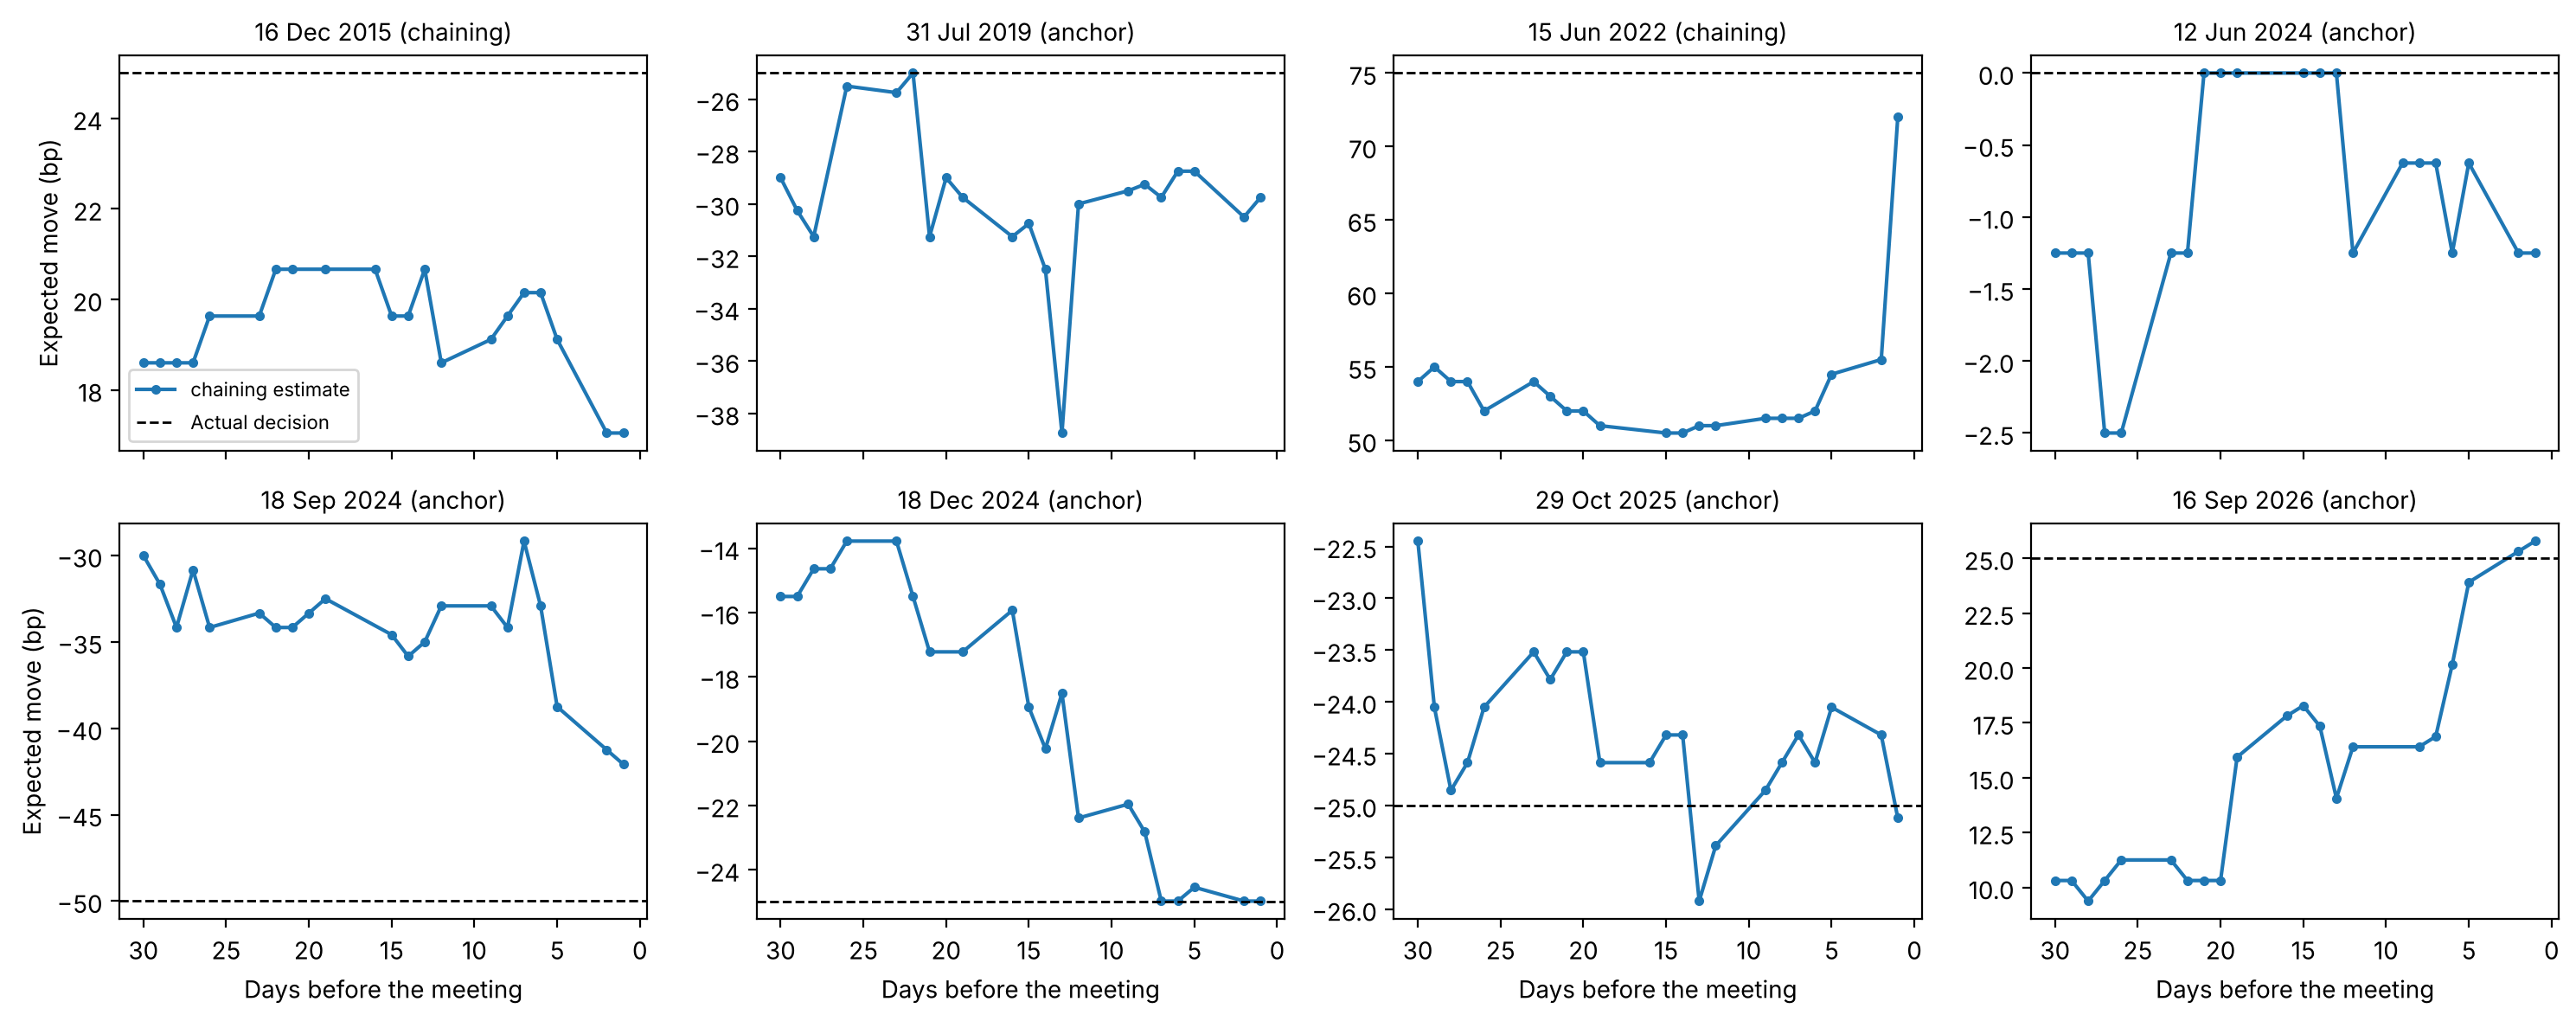

In [6]:
FIGURES.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 4, figsize=(15, 6), sharex=True)

for ax, meeting in zip(axes.flat, meetings):
    days = px.index[(px.index >= meeting - pd.Timedelta(days=30)) & (px.index < meeting)]
    method = "anchor" if anchor_usable(meeting) else "chaining"

    expected_moves = []
    for observation_date in days:
        old_rate, new_rate = expected_rates(observation_date, meeting, method)
        expected_moves.append(100 * (new_rate - old_rate))

    ax.plot((meeting - days).days, expected_moves, marker="o", markersize=3, label=f"{method} estimate")
    ax.axhline(realised_move_bp(meeting), linestyle="--", color="black", linewidth=1, label="Actual decision")
    ax.set_title(f"{meeting:%d %b %Y} ({method})", fontsize=10)

for ax in axes[:, 0]:
    ax.set_ylabel("Expected move (bp)")
for ax in axes[1]:
    ax.set_xlabel("Days before the meeting")

axes[0, 0].legend(fontsize=8)
axes[0, 0].invert_xaxis()
fig.tight_layout()
fig.savefig(FIGURES / "mission3_expectations_before_fomc.png", bbox_inches="tight")
plt.show()

For December 2024, October 2025 and September 2026, the expected move gets close to the actual decision before the meeting. In June 2022, the estimate stays near +50 bp for much of the month and reaches +72 bp only in the last days.

In September 2024, the estimate rises in size from around −30 bp to −42 bp just before the meeting, but the full 50 bp cut is not priced. In December 2015, the expected increase stays around 17–20 bp, which suggests that a 25 bp increase was likely but not certain.

## 6. All scheduled meetings, 2015–2026

The same calculation is applied to all scheduled meetings covered by the futures and target-rate data. The anchor is preferred when usable, otherwise chaining is used. Errors are compared across observation horizons, periods and types of decisions.

In [7]:
in_range = scheduled[(scheduled > policy_rate.index.min()) & (scheduled <= px.index.max())]
dropped = [m.date() for m in in_range if other_decision_in_month(m)]
print("Dropped (another decision in the same month):", dropped)
sample = pd.DatetimeIndex([m for m in in_range if not other_decision_in_month(m)])

full = build_table(sample)
full["method"] = np.where(full["anchor_usable"], "anchor",
                          np.where(full["chaining_usable"], "chaining", None))
full["implied_rate_pct"] = np.where(full["method"] == "anchor", full["anchor_implied_rate_pct"],
                                    full["chaining_implied_rate_pct"])
full["expected_change_bp"] = np.where(full["method"] == "anchor", full["anchor_expected_change_bp"],
                                      full["chaining_expected_change_bp"])
full = full.dropna(subset=["method", "expected_change_bp"]).copy()
full["error_bp"] = full["realised_change_bp"] - full["expected_change_bp"]
full["period"] = pd.cut(
    full["fomc_meeting_date"],
    pd.to_datetime(["2015-01-01", "2020-01-01", "2022-01-01", "2030-01-01"]),
    right=False,
    labels=["2015-2019 normalisation", "2020-2021 zero rates", "2022-2026 hikes and cuts"],
)
full["decision"] = np.select(
    [full["realised_change_bp"] > 0, full["realised_change_bp"] < 0], ["increase", "cut"], "no change"
)

print(f"{len(in_range)} scheduled meetings, "
      f"{full['fomc_meeting_date'].nunique()} kept")
print(full.drop_duplicates("fomc_meeting_date")["method"].value_counts().to_string())


def error_stats(group):
    errors = group["error_bp"].abs()
    return pd.Series({
        "meetings": group["fomc_meeting_date"].nunique(),
        "MAE (bp)": errors.mean(),
        "median abs. error (bp)": errors.median(),
        "within 5 bp (%)": 100 * (errors <= 5).mean(),
    })


by_horizon = full.groupby("horizon")[["fomc_meeting_date", "error_bp"]].apply(error_stats)
display(by_horizon.reindex(["t-30", "t-7", "t-1"]).round(1))

t1 = full[full["horizon"] == "t-1"]
display(t1.groupby("period", observed=True)[["fomc_meeting_date", "error_bp"]].apply(error_stats).round(1))
display(t1.groupby("decision")[["fomc_meeting_date", "error_bp"]].apply(error_stats)
        .reindex(["increase", "cut", "no change"]).round(1))

Dropped (another decision in the same month): []


94 scheduled meetings, 94 kept
method
anchor      69
chaining    25


,meetings,MAE (bp),median abs. error (bp),within 5 bp (%)
horizon,,,,
t-30,94.00,3.90,1.70,74.50
t-7,94.00,2.30,1.00,87.20
t-1,94.00,1.60,0.80,93.60


,meetings,MAE (bp),median abs. error (bp),within 5 bp (%)
period,,,,
2015-2019 normalisation,40.00,1.80,0.90,90.00
2020-2021 zero rates,15.00,1.00,0.80,100.00
2022-2026 hikes and cuts,39.00,1.60,0.80,94.90


,meetings,MAE (bp),median abs. error (bp),within 5 bp (%)
decision,,,,
increase,21.00,2.70,2.00,90.50
cut,9.00,2.50,1.50,88.90
no change,64.00,1.20,0.60,95.30


**Largest errors one day before the meeting.**

,method,expected_change_bp,realised_change_bp,error_bp
fomc_meeting_date,,,,
2015-12-16,chaining,17.00,25,8.00
2024-09-18,anchor,-42.10,-50,-7.90
2018-12-19,anchor,17.10,25,7.90
2026-07-29,anchor,7.80,0,-7.80
2015-09-17,anchor,5.30,0,-5.30
2019-06-19,anchor,-5.10,0,5.10
2019-07-31,anchor,-29.70,-25,4.70
2022-09-21,anchor,79.60,75,-4.60


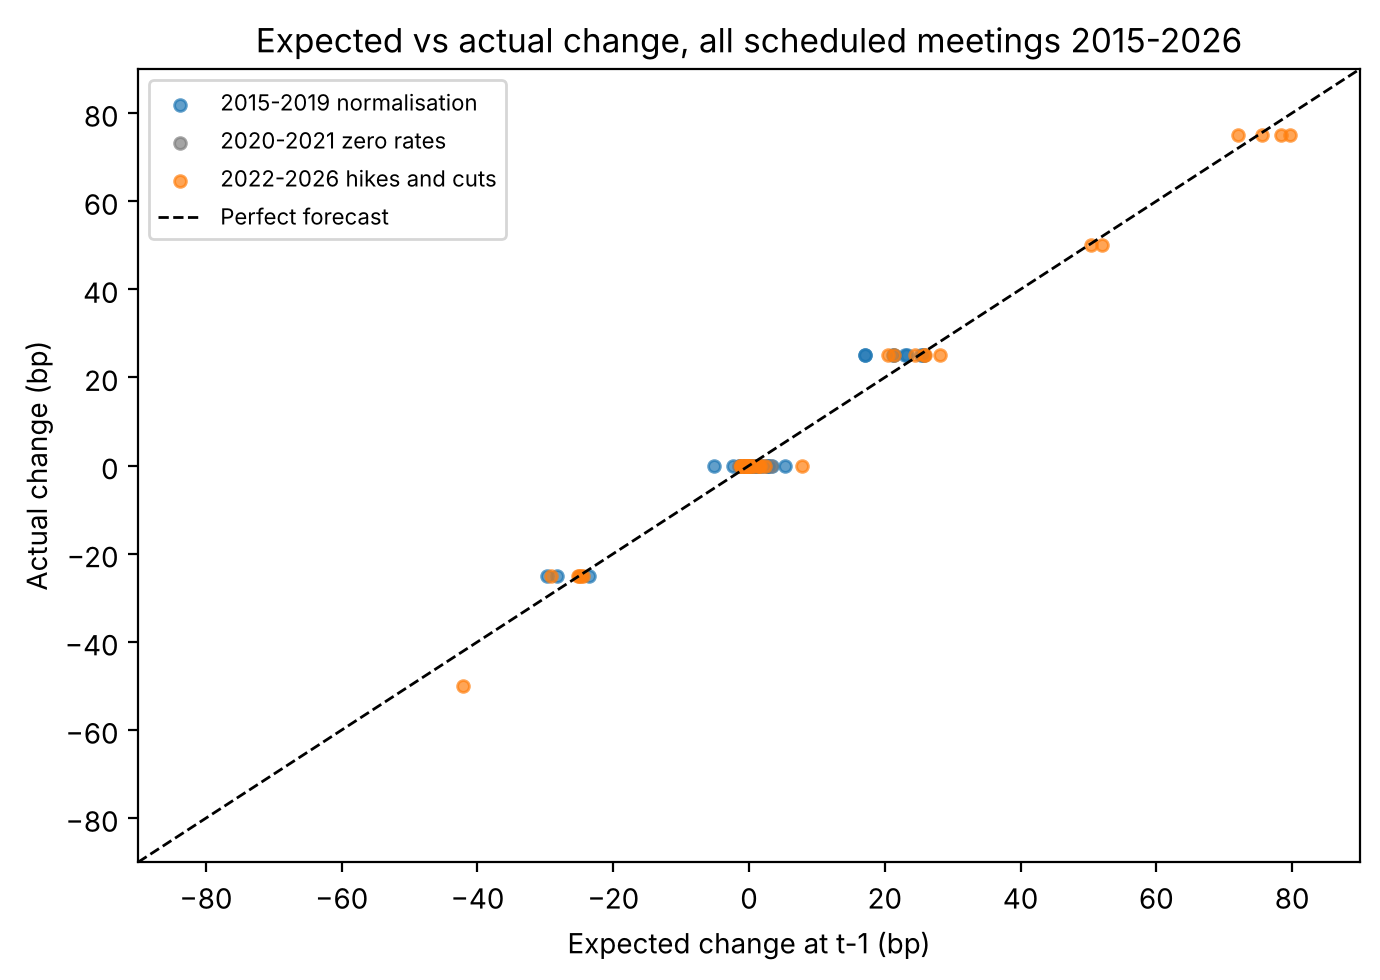

In [8]:
largest = t1.reindex(t1["error_bp"].abs().sort_values(ascending=False).index).head(8)
display(
    largest[["fomc_meeting_date", "method", "expected_change_bp", "realised_change_bp", "error_bp"]]
    .assign(fomc_meeting_date=largest["fomc_meeting_date"].dt.date)
    .set_index("fomc_meeting_date").round(1)
)

fig, ax = plt.subplots(figsize=(7, 5))
colors = {"2015-2019 normalisation": "tab:blue", "2020-2021 zero rates": "tab:gray",
          "2022-2026 hikes and cuts": "tab:orange"}
for period, group in t1.groupby("period", observed=True):
    ax.scatter(group["expected_change_bp"], group["realised_change_bp"], s=18,
               alpha=0.7, color=colors[period], label=period)
lims = [-90, 90]
ax.plot(lims, lims, color="black", linewidth=1, linestyle="--", label="Perfect forecast")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Expected change at t-1 (bp)")
ax.set_ylabel("Actual change (bp)")
ax.set_title("Expected vs actual change, all scheduled meetings 2015-2026")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "mission3_expected_vs_actual_all_meetings.png", bbox_inches="tight")
plt.show()

Across 94 meetings, the MAE falls from 3.9 bp at $t-30$ to 1.6 bp at $t-1$. One day before the meeting, the median absolute error is 0.8 bp and about 94% of estimates are within 5 bp of the decision.

Errors are generally small across the three periods. They are lowest in 2020–2021, when rates stayed near zero. Increases and cuts are harder to estimate than unchanged decisions. The largest errors, around 8 bp, include December 2015, December 2018 and September 2024.

## 7. Cross-check with Mission 1 (FedWatch replication)

The comparison uses `data/fedwatch_replication/historical_meeting_probabilities.csv`. For matching observation dates and meetings, the anchor implied rate is compared with `post_effr_pct` from the FedWatch replication.

In [9]:
mission1 = pd.read_csv(
    DATA / "fedwatch_replication" / "historical_meeting_probabilities.csv",
    parse_dates=["observation_date", "fomc_meeting_date"],
).drop_duplicates(["observation_date", "fomc_meeting_date"])

common = full[full["method"] == "anchor"].merge(
    mission1[["observation_date", "fomc_meeting_date", "post_effr_pct"]],
    on=["observation_date", "fomc_meeting_date"],
)
common["gap_bp"] = 100 * (common["anchor_implied_rate_pct"] - common["post_effr_pct"])

print(f"{len(common)} common observations on {common['fomc_meeting_date'].nunique()} meetings")
print(f"Largest gap between the two notebooks: {common['gap_bp'].abs().max():.6f} bp")

121 common observations on 44 meetings
Largest gap between the two notebooks: 0.000000 bp


The implied rates match for all common observations. The two calculations are therefore consistent on this sample. Mission 1 converts implied rates into probabilities, while Mission 3 compares earlier expectations with the later decisions.

## 8. Exported files

The exported files use the common column names, including `observation_date`, `fomc_meeting_date`, `contract_id`, `futures_price`, `implied_rate_pct` and `expected_change_bp`.

In [10]:
HISTORY.mkdir(parents=True, exist_ok=True)

# 1. Dated futures prices used for the eight case studies
prices = []
for meeting in meetings:
    for month_offset in [0, 1]:
        contract = contract_id(meeting.to_period("M") + month_offset)
        series = px.loc[meeting - pd.Timedelta(days=35): meeting - pd.Timedelta(days=1), contract].dropna()
        prices.append(pd.DataFrame({
            "observation_date": series.index.date,
            "fomc_meeting_date": meeting.date(),
            "contract_id": contract,
            "instrument": "30D_FED_FUNDS_FUTURE",
            "source": "Bloomberg",
            "price_type": "settlement",
            "futures_price": series.values,
            "implied_rate_pct": 100 - series.values,
        }))
prices = pd.concat(prices, ignore_index=True)
prices.to_csv(HISTORY / "dated_futures_prices.csv", index=False, float_format="%.4f")

# 2. Case-study table (both methods)
table.to_csv(HISTORY / "expectations_t30_t7_t1.csv", index=False, float_format="%.4f",
             date_format="%Y-%m-%d")

# 3. All meetings, preferred method
full[["observation_date", "fomc_meeting_date", "horizon", "method", "implied_rate_pct",
      "expected_change_bp", "realised_change_bp", "error_bp", "period", "decision"]].to_csv(
    HISTORY / "expectations_all_meetings.csv", index=False, float_format="%.4f", date_format="%Y-%m-%d")

print(f"Exported {len(prices)} dated prices, {len(table)} case-study estimates "
      f"and {len(full)} estimates for all meetings")

Exported 386 dated prices, 24 case-study estimates and 282 estimates for all meetings


## 9. Conclusion

Daily Fed Funds futures prices can be used to reconstruct the rates expected before past FOMC meetings. The anchor and chaining methods are useful in different situations, especially when meetings fall near the start or end of a month.

For the 94 scheduled meetings studied from 2015 to 2026, the estimates become more accurate as the meeting approaches. At $t-1$, the median absolute error is 0.8 bp and about 94% of estimates are within 5 bp of the decision. The largest differences are linked to increases or cuts that were not fully expected. The implied rates also match the FedWatch replication on common observations.

**Limits.** Futures prices give an expected monthly rate, not a full probability distribution. They may also include a term premium. The study begins in 2015 because the target-midpoint data used here starts then. The sample excludes meetings with another decision in the same month. Finally, decisions are measured with the Fed target midpoint, while futures refer to EFFR. These rates generally move together, but they are not identical.